In [1]:
# ============================================================
# STAGE 7 - CELL 1: Imports and Load Existing Data/Models
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, Dropout,
    Bidirectional, LSTM, Dense, Flatten
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)

import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(42)
tf.random.set_seed(42)

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size']      = 11
sns.set_theme(style="whitegrid")

# ── Paths (corrected to your new machine's username) ───────────
PROJECT_ROOT = "C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project"
RESULTS_DIR  = os.path.join(PROJECT_ROOT, "results")
MODELS_DIR   = os.path.join(PROJECT_ROOT, "models")
PLOTS_DIR    = os.path.join(PROJECT_ROOT, "plots")
SEQ_DIR      = os.path.join(RESULTS_DIR, "sequences")

CITIES = ['kano', 'maid', 'abuja']
CITY_LABELS = {'kano': 'Kano', 'maid': 'Maiduguri', 'abuja': 'Abuja'}

# ── Reload sequences (same splits used for CNN-biLSTM and XGBoost) ─
data = {}
for city in CITIES:
    data[city] = {
        'X_train': np.load(os.path.join(SEQ_DIR, f'X_train_{city}.npy')),
        'y_train': np.load(os.path.join(SEQ_DIR, f'y_train_{city}.npy')),
        'X_val':   np.load(os.path.join(SEQ_DIR, f'X_val_{city}.npy')),
        'y_val':   np.load(os.path.join(SEQ_DIR, f'y_val_{city}.npy')),
        'X_test':  np.load(os.path.join(SEQ_DIR, f'X_test_{city}.npy')),
        'y_test':  np.load(os.path.join(SEQ_DIR, f'y_test_{city}.npy')),
        'tgt_scaler': joblib.load(os.path.join(MODELS_DIR, f'tgt_scaler_{city}.pkl')),
    }

WINDOW_SIZE = data['kano']['X_train'].shape[1]   # 24
N_FEATURES  = data['kano']['X_train'].shape[2]   # 17

print("="*55)
print("STAGE 7: RESULTS, PLOTS, AND EVALUATION")
print("="*55)
print(f"Window size: {WINDOW_SIZE}, Features: {N_FEATURES}")
for city in CITIES:
    print(f"{CITY_LABELS[city]:10s} — Train: {data[city]['X_train'].shape[0]:,} | "
          f"Val: {data[city]['X_val'].shape[0]:,} | Test: {data[city]['X_test'].shape[0]:,}")

STAGE 7: RESULTS, PLOTS, AND EVALUATION
Window size: 24, Features: 17
Kano       — Train: 52,560 | Val: 8,736 | Test: 8,736
Maiduguri  — Train: 52,560 | Val: 8,736 | Test: 8,736
Abuja      — Train: 52,560 | Val: 8,736 | Test: 8,736


In [2]:
# ============================================================
# CLEAN RUN - CELL 1: Delete Unstable Baseline Model Files
# ============================================================

import glob

files_to_delete = []
for city in CITIES:
    files_to_delete += glob.glob(os.path.join(MODELS_DIR, f'best_cnn_only_{city}.keras'))
    files_to_delete += glob.glob(os.path.join(MODELS_DIR, f'best_lstm_only_{city}.keras'))
    files_to_delete += glob.glob(os.path.join(MODELS_DIR, f'best_cnn_lstm_{city}.keras'))
    files_to_delete += glob.glob(os.path.join(MODELS_DIR, f'xgb_only_{city}.pkl'))

print(f"Found {len(files_to_delete)} file(s) to remove:\n")
for f in files_to_delete:
    print(f"  {f}")
    os.remove(f)

print(f"\n✅ Deleted. These will be freshly retrained on the next run.")

Found 12 file(s) to remove:

  C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project\models\best_cnn_only_kano.keras
  C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project\models\best_lstm_only_kano.keras
  C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project\models\best_cnn_lstm_kano.keras
  C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project\models\xgb_only_kano.pkl
  C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project\models\best_cnn_only_maid.keras
  C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project\models\best_lstm_only_maid.keras
  C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project\models\best_cnn_lstm_maid.keras
  C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project\models\xgb_only_maid.pkl
  C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project\models\best_cnn_only_abuja.keras
  C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project\models\best_lstm_only_abuja.keras
  C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project\models\best_cnn_lstm_abuja.keras


In [3]:
# ============================================================
# STAGE 7 - CELL 2 (EXPANDED): Shared Evaluation Function
# ============================================================

def evaluate_model(y_pred_norm, y_test_norm, tgt_scaler):
    """
    Converts normalised predictions/targets back to real kW,
    then computes RMSE, MAE, MAPE, R², nRMSE, and nMAE —
    restricted to daytime hours only (actual power > 0),
    matching the convention used in Stage 4 and Stage 5.
    """
    y_pred_kw = tgt_scaler.inverse_transform(y_pred_norm.reshape(-1, 1)).flatten()
    y_true_kw = tgt_scaler.inverse_transform(y_test_norm.reshape(-1, 1)).flatten()

    mask = y_true_kw > 0
    y_true_day = y_true_kw[mask]
    y_pred_day = y_pred_kw[mask]

    rmse = np.sqrt(mean_squared_error(y_true_day, y_pred_day))
    mae  = mean_absolute_error(y_true_day, y_pred_day)
    mape = np.mean(np.abs((y_true_day - y_pred_day) / (y_true_day + 1e-8))) * 100
    r2   = r2_score(y_true_day, y_pred_day)

    mean_actual = y_true_day.mean()
    nrmse = (rmse / mean_actual) * 100
    nmae  = (mae / mean_actual) * 100

    return {
        'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'R2': r2,
        'nRMSE': nrmse, 'nMAE': nmae
    }

# ── This line must sit at ZERO indentation — outside the function ──
results = {city: {} for city in CITIES}

In [4]:
# ============================================================
# STAGE 7 - CELL 3: Shared Callback Builder
# ============================================================

def get_callbacks(model_tag, city_name):
    early_stop = EarlyStopping(
        monitor='val_loss', patience=15,
        restore_best_weights=True, verbose=0
    )
    reduce_lr = ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=7, min_lr=1e-6, verbose=0
    )
    checkpoint_path = os.path.join(MODELS_DIR, f'best_{model_tag}_{city_name}.keras')
    checkpoint = ModelCheckpoint(
        filepath=checkpoint_path, monitor='val_loss',
        save_best_only=True, verbose=0
    )
    return [early_stop, reduce_lr, checkpoint], checkpoint_path

In [5]:
# ============================================================
# LEVER 3 DIAGNOSTIC - CELL 1: Compute Residuals on Training Data
# ============================================================

from sklearn.model_selection import KFold, cross_val_score

residual_diagnostics = {}

for city in CITIES:
    print(f"Computing residuals — {CITY_LABELS[city]}...")

    cnn_bilstm_model = load_model(
        os.path.join(MODELS_DIR, f'best_cnn_bilstm_{CITY_LABELS[city].lower()}.keras')
    )

    y_pred_train_norm = cnn_bilstm_model.predict(data[city]['X_train'], verbose=0).flatten()

    tgt_scaler = data[city]['tgt_scaler']
    y_pred_train_kw = tgt_scaler.inverse_transform(y_pred_train_norm.reshape(-1, 1)).flatten()
    y_true_train_kw = tgt_scaler.inverse_transform(data[city]['y_train'].reshape(-1, 1)).flatten()

    residual = y_true_train_kw - y_pred_train_kw

    mask = y_true_train_kw > 0
    residual_day = residual[mask]
    X_features_day = data[city]['X_train'][:, -1, :][mask]

    residual_diagnostics[city] = {
        'residual': residual_day,
        'features': X_features_day,
    }

    print(f"  Daytime samples: {len(residual_day):,} | "
          f"Residual mean: {residual_day.mean():.2f} kW | "
          f"Residual std: {residual_day.std():.2f} kW\n")

Computing residuals — Kano...
  Daytime samples: 27,297 | Residual mean: 12.80 kW | Residual std: 36.44 kW

Computing residuals — Maiduguri...
  Daytime samples: 26,926 | Residual mean: 19.30 kW | Residual std: 54.09 kW

Computing residuals — Abuja...
  Daytime samples: 27,427 | Residual mean: 17.93 kW | Residual std: 43.85 kW



In [6]:
# ============================================================
# LEVER 3 DIAGNOSTIC - CELL 2: Feature-Residual Correlation
# ============================================================

FEATURE_NAMES_17 = [
    'GHI', 'DHI', 'Clearness',
    'Temperature', 'Humidity', 'WindSpeed',
    'Hour_sin', 'Hour_cos',
    'Month_sin', 'Month_cos',
    'DayOfYear_sin', 'DayOfYear_cos',
    'Season_encoded', 'Is_Daytime',
    'PV_Power_Lag1', 'PV_Power_Lag24', 'GHI_Lag1'
]

for city in CITIES:
    residual = residual_diagnostics[city]['residual']
    features = residual_diagnostics[city]['features']

    correlations = []
    for i, fname in enumerate(FEATURE_NAMES_17):
        corr = np.corrcoef(features[:, i], residual)[0, 1]
        correlations.append((fname, corr))

    corr_df = pd.DataFrame(correlations, columns=['Feature', 'Correlation'])
    corr_df['Abs_Correlation'] = corr_df['Correlation'].abs()
    corr_df = corr_df.sort_values('Abs_Correlation', ascending=False).drop(columns='Abs_Correlation')

    print(f"\n{'='*45}")
    print(f"FEATURE-RESIDUAL CORRELATION — {CITY_LABELS[city]}")
    print(f"{'='*45}")
    print(corr_df.to_string(index=False))


FEATURE-RESIDUAL CORRELATION — Kano
       Feature  Correlation
           GHI     0.406049
PV_Power_Lag24     0.356917
      GHI_Lag1     0.353284
 PV_Power_Lag1     0.353209
     Clearness     0.342785
           DHI     0.327527
   Temperature     0.323314
      Hour_cos    -0.311384
    Is_Daytime     0.178195
Season_encoded     0.145342
     Month_cos    -0.132182
 DayOfYear_cos    -0.127786
      Hour_sin    -0.107474
      Humidity    -0.099127
 DayOfYear_sin     0.044116
     WindSpeed     0.030003
     Month_sin     0.010483

FEATURE-RESIDUAL CORRELATION — Maiduguri
       Feature  Correlation
 DayOfYear_cos     0.515381
     Month_cos     0.476374
      Humidity    -0.333113
      Hour_sin     0.228833
     Clearness     0.202832
     Month_sin     0.195554
     WindSpeed     0.183806
Season_encoded    -0.174967
           GHI     0.170596
   Temperature    -0.166944
PV_Power_Lag24     0.135876
           DHI     0.069074
 DayOfYear_sin     0.062822
 PV_Power_Lag1     0.0409

In [7]:
# ============================================================
# LEVER 3 DIAGNOSTIC - CELL 3: Cross-Validated "Learnability" Test
# ============================================================

print("="*55)
print("RESIDUAL LEARNABILITY TEST (5-fold Cross-Validation)")
print("="*55)
print("\nThis answers: 'How well could a model predict the CNN's")
print("error, using only these 17 features?' Measured in R².\n")

learnability_results = {}

for city in CITIES:
    residual = residual_diagnostics[city]['residual']
    features = residual_diagnostics[city]['features']

    quick_model = xgb.XGBRegressor(
        n_estimators=200, max_depth=4, learning_rate=0.05,
        random_state=42, n_jobs=-1, verbosity=0
    )

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(quick_model, features, residual, cv=kf, scoring='r2')

    learnability_results[city] = cv_scores

    print(f"{CITY_LABELS[city]}:")
    print(f"  Cross-validated R² per fold: {np.round(cv_scores, 4)}")
    print(f"  Mean R²: {cv_scores.mean():.4f} (±{cv_scores.std():.4f})\n")

RESIDUAL LEARNABILITY TEST (5-fold Cross-Validation)

This answers: 'How well could a model predict the CNN's
error, using only these 17 features?' Measured in R².

Kano:
  Cross-validated R² per fold: [0.4039 0.3928 0.3625 0.3931 0.3631]
  Mean R²: 0.3831 (±0.0170)

Maiduguri:
  Cross-validated R² per fold: [0.6055 0.6269 0.6407 0.6311 0.622 ]
  Mean R²: 0.6252 (±0.0116)

Abuja:
  Cross-validated R² per fold: [0.4532 0.4929 0.4896 0.4585 0.485 ]
  Mean R²: 0.4758 (±0.0166)



In [8]:
# ============================================================
# STAGE 7 - CELL 4: Baseline Architectures (CNN-only, LSTM-only, CNN-LSTM)
# ============================================================

def build_cnn_only(window_size, n_features,
                    filters=64, kernel_size=5,
                    dropout_rate=0.10, learning_rate=0.001):
    inputs = Input(shape=(window_size, n_features), name='Input_Layer')

    x = Conv1D(filters, kernel_size, activation='relu', padding='same')(inputs)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    x = Conv1D(filters, kernel_size, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    x = Flatten()(x)
    x = Dense(32, activation='relu')(x)
    outputs = Dense(1, name='Output')(x)

    model = Model(inputs, outputs, name='CNN_Only')
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='mse', metrics=['mae'])
    return model


def build_lstm_only(window_size, n_features,
                     lstm_units=64, dropout_rate=0.10, learning_rate=0.001):
    inputs = Input(shape=(window_size, n_features), name='Input_Layer')

    x = LSTM(lstm_units, name='LSTM_Layer')(inputs)
    x = Dropout(dropout_rate)(x)
    x = Dense(32, activation='relu')(x)
    outputs = Dense(1, name='Output')(x)

    model = Model(inputs, outputs, name='LSTM_Only')
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='mse', metrics=['mae'])
    return model


def build_cnn_lstm(window_size, n_features,
                    filters=64, kernel_size=5, lstm_units=64,
                    dropout_rate=0.10, learning_rate=0.001):
    inputs = Input(shape=(window_size, n_features), name='Input_Layer')

    x = Conv1D(filters, kernel_size, activation='relu', padding='same')(inputs)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    x = Conv1D(filters, kernel_size, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    x = LSTM(lstm_units, name='LSTM_Layer')(x)
    x = Dropout(dropout_rate)(x)
    outputs = Dense(1, name='Output')(x)

    model = Model(inputs, outputs, name='CNN_LSTM')
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='mse', metrics=['mae'])
    return model

print("✅ Three baseline architectures defined")

✅ Three baseline architectures defined


In [9]:
# ============================================================
# STAGE 7 - CELL 5 (REVISED): Train or Load Baseline NN Models
# ============================================================

builders = {
    'cnn_only':  build_cnn_only,
    'lstm_only': build_lstm_only,
    'cnn_lstm':  build_cnn_lstm,
}

trained_models = {}

for arch_name, builder_fn in builders.items():
    trained_models[arch_name] = {}
    for city in CITIES:
        checkpoint_path = os.path.join(MODELS_DIR, f'best_{arch_name}_{city}.keras')

        # ── Check if this model was already trained in a previous session ──
        if os.path.exists(checkpoint_path):
            print(f"✅ Found existing model — loading {arch_name.upper()} ({CITY_LABELS[city]}) from disk...")
            model = load_model(checkpoint_path)
            trained_models[arch_name][city] = model
            continue   # skip straight to the next city — no training needed

        # ── No saved file found — train it fresh, same as before ──
        print("="*55)
        print(f"TRAINING {arch_name.upper()} — {CITY_LABELS[city].upper()} (no saved model found)")
        print("="*55)

        model = builder_fn(WINDOW_SIZE, N_FEATURES)
        callbacks, ckpt_path = get_callbacks(arch_name, city)

        history = model.fit(
            data[city]['X_train'], data[city]['y_train'],
            validation_data=(data[city]['X_val'], data[city]['y_val']),
            epochs=120, batch_size=64,
            callbacks=callbacks,
            verbose=0,
            shuffle=False
        )

        trained_models[arch_name][city] = model
        print(f"Epochs trained: {len(history.history['loss'])} | "
              f"Best val_loss: {min(history.history['val_loss']):.6f}\n")

print("\n✅ All 9 baseline models ready (loaded from disk or freshly trained)")

TRAINING CNN_ONLY — KANO (no saved model found)
Epochs trained: 27 | Best val_loss: 0.003394

TRAINING CNN_ONLY — MAIDUGURI (no saved model found)
Epochs trained: 31 | Best val_loss: 0.004390

TRAINING CNN_ONLY — ABUJA (no saved model found)
Epochs trained: 34 | Best val_loss: 0.003307

TRAINING LSTM_ONLY — KANO (no saved model found)
Epochs trained: 74 | Best val_loss: 0.000739

TRAINING LSTM_ONLY — MAIDUGURI (no saved model found)
Epochs trained: 52 | Best val_loss: 0.000837

TRAINING LSTM_ONLY — ABUJA (no saved model found)
Epochs trained: 46 | Best val_loss: 0.000881

TRAINING CNN_LSTM — KANO (no saved model found)
Epochs trained: 27 | Best val_loss: 0.001925

TRAINING CNN_LSTM — MAIDUGURI (no saved model found)
Epochs trained: 19 | Best val_loss: 0.002505

TRAINING CNN_LSTM — ABUJA (no saved model found)
Epochs trained: 39 | Best val_loss: 0.001761


✅ All 9 baseline models ready (loaded from disk or freshly trained)


In [10]:
# ============================================================
# STAGE 7 - CELL 6 (REVISED): Train or Load Standalone XGBoost
# ============================================================

XGB_PARAMS = {
    'n_estimators'      : 300,
    'max_depth'         : 4,
    'learning_rate'     : 0.05,
    'subsample'         : 0.8,
    'colsample_bytree'  : 0.8,
    'min_child_weight'  : 5,
    'reg_alpha'         : 0.1,
    'reg_lambda'        : 1.0,
    'objective'         : 'reg:squarederror',
    'random_state'      : 42,
    'n_jobs'            : -1,
    'verbosity'         : 0
}

trained_models['xgb_only'] = {}

for city in CITIES:
    save_path = os.path.join(MODELS_DIR, f'xgb_only_{city}.pkl')

    # ── Check if this model was already trained in a previous session ──
    if os.path.exists(save_path):
        print(f"✅ Found existing model — loading standalone XGBoost ({CITY_LABELS[city]}) from disk...")
        model = joblib.load(save_path)
        trained_models['xgb_only'][city] = model
        continue

    # ── No saved file found — train it fresh, same as before ──
    print(f"Training standalone XGBoost — {CITY_LABELS[city]} (no saved model found)...")

    X_train_flat = data[city]['X_train'][:, -1, :]
    X_val_flat   = data[city]['X_val'][:, -1, :]

    model = xgb.XGBRegressor(**XGB_PARAMS)
    model.fit(
        X_train_flat, data[city]['y_train'],
        eval_set=[(X_val_flat, data[city]['y_val'])],
        verbose=False
    )

    trained_models['xgb_only'][city] = model
    joblib.dump(model, save_path)   # ← save it now, so next session can load it
    print(f"✅ {CITY_LABELS[city]} trained and saved: xgb_only_{city}.pkl\n")

print("\n✅ Standalone XGBoost ready for all cities (loaded from disk or freshly trained)")

Training standalone XGBoost — Kano (no saved model found)...
✅ Kano trained and saved: xgb_only_kano.pkl

Training standalone XGBoost — Maiduguri (no saved model found)...
✅ Maiduguri trained and saved: xgb_only_maid.pkl

Training standalone XGBoost — Abuja (no saved model found)...
✅ Abuja trained and saved: xgb_only_abuja.pkl


✅ Standalone XGBoost ready for all cities (loaded from disk or freshly trained)


In [11]:
# ============================================================
# STAGE 7 - CELL 7 (CORRECTED): Generate Predictions and Evaluate All Models
# ============================================================

# ── Baseline NN models (CNN-only, LSTM-only, CNN-LSTM) ─────────
for arch_name in ['cnn_only', 'lstm_only', 'cnn_lstm']:
    for city in CITIES:
        model = trained_models[arch_name][city]
        y_pred_norm = model.predict(data[city]['X_test'], verbose=0).flatten()
        results[city][arch_name] = evaluate_model(
            y_pred_norm, data[city]['y_test'], data[city]['tgt_scaler']
        )

# ── Standalone XGBoost ──────────────────────────────────────────
for city in CITIES:
    model = trained_models['xgb_only'][city]
    X_test_flat = data[city]['X_test'][:, -1, :]
    y_pred_norm = model.predict(X_test_flat)
    results[city]['xgb_only'] = evaluate_model(
        y_pred_norm, data[city]['y_test'], data[city]['tgt_scaler']
    )

# ── Existing models: CNN-biLSTM (Stage 4) and Hybrid (Stage 5) ──
for city in CITIES:
    cnn_bilstm_model = load_model(
        os.path.join(MODELS_DIR, f'best_cnn_bilstm_{CITY_LABELS[city].lower()}.keras')
    )
    y_pred_norm = cnn_bilstm_model.predict(data[city]['X_test'], verbose=0).flatten()
    results[city]['cnn_bilstm'] = evaluate_model(
        y_pred_norm, data[city]['y_test'], data[city]['tgt_scaler']
    )

    # Hybrid predictions (loaded from Stage 5's saved .npy files)
    y_pred_hybrid_kw = np.load(os.path.join(RESULTS_DIR, f'y_pred_hybrid_{city}.npy'))
    y_true_kw = data[city]['tgt_scaler'].inverse_transform(
        data[city]['y_test'].reshape(-1, 1)).flatten()

    mask = y_true_kw > 0
    y_true_day = y_true_kw[mask]
    y_pred_day = y_pred_hybrid_kw[mask]

    rmse = np.sqrt(mean_squared_error(y_true_day, y_pred_day))
    mae  = mean_absolute_error(y_true_day, y_pred_day)
    mape = np.mean(np.abs((y_true_day - y_pred_day) / (y_true_day + 1e-8))) * 100
    r2   = r2_score(y_true_day, y_pred_day)
    mean_actual = y_true_day.mean()
    nrmse = (rmse / mean_actual) * 100
    nmae  = (mae / mean_actual) * 100

    results[city]['hybrid'] = {
        'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'R2': r2,
        'nRMSE': nrmse, 'nMAE': nmae
    }

print("✅ All 6 models re-evaluated using daytime-only convention (matching Stage 4/5)")

✅ All 6 models re-evaluated using daytime-only convention (matching Stage 4/5)


In [12]:
# ============================================================
# LEVER 1 - CELL 1: Build Enhanced Feature Set
# ============================================================

# Feature index reference (from Stage 3's INPUT_FEATURES order)
FEATURE_INDEX = {name: i for i, name in enumerate(FEATURE_NAMES_17)}
GHI_IDX       = FEATURE_INDEX['GHI']
HUMIDITY_IDX  = FEATURE_INDEX['Humidity']
CLEARNESS_IDX = FEATURE_INDEX['Clearness']

def build_enhanced_features(X_sequences, cnn_pred_norm):
    """
    Takes a batch of 24-hour sequences and builds the Lever 1
    feature set: the original 17 last-timestep features, PLUS
    the CNN-biLSTM's prediction, PLUS new rolling-window
    summaries for the 3 features our diagnostic flagged as
    most correlated with the CNN-biLSTM's errors.
    """
    # 1) Original 17 last-timestep features — unchanged from Stage 5
    last_timestep = X_sequences[:, -1, :]                     # shape (N, 17)

    # 2) CNN-biLSTM's own prediction — unchanged from Stage 5
    cnn_pred_col = cnn_pred_norm.reshape(-1, 1)                # shape (N, 1)

    # 3) NEW: rolling mean and std, over the last 3 hours and last 6 hours,
    #    for GHI, Humidity, and Clearness specifically — chosen because
    #    these were the features most correlated with the CNN's mistakes
    #    in our Lever 3 diagnostic (varies slightly by city, but these
    #    three covered the top signals across all three cities combined).
    rolling_features = []
    rolling_names = []

    for window in [3, 6]:
        recent_window = X_sequences[:, -window:, :]            # last `window` hours

        for feat_idx, feat_name in [(GHI_IDX, 'GHI'),
                                      (HUMIDITY_IDX, 'Humidity'),
                                      (CLEARNESS_IDX, 'Clearness')]:
            mean_val = recent_window[:, :, feat_idx].mean(axis=1)   # shape (N,)
            std_val  = recent_window[:, :, feat_idx].std(axis=1)    # shape (N,)

            rolling_features.append(mean_val)
            rolling_features.append(std_val)
            rolling_names.append(f'{feat_name}_mean_{window}h')
            rolling_names.append(f'{feat_name}_std_{window}h')

    rolling_matrix = np.column_stack(rolling_features)          # shape (N, 12)

    # Stitch everything together: 17 + 1 + 12 = 30 total features
    enhanced = np.hstack([last_timestep, cnn_pred_col, rolling_matrix])

    feature_names_v2 = FEATURE_NAMES_17 + ['CNN_Prediction'] + rolling_names

    return enhanced, feature_names_v2


# ── Build the enhanced feature sets for all three cities ───────
enhanced_data = {}

for city in CITIES:
    print(f"Building enhanced features — {CITY_LABELS[city]}...")

    cnn_bilstm_model = load_model(
        os.path.join(MODELS_DIR, f'best_cnn_bilstm_{CITY_LABELS[city].lower()}.keras')
    )

    # Get CNN-biLSTM predictions for train, val, and test sets
    cnn_pred_train = cnn_bilstm_model.predict(data[city]['X_train'], verbose=0).flatten()
    cnn_pred_val   = cnn_bilstm_model.predict(data[city]['X_val'],   verbose=0).flatten()
    cnn_pred_test  = cnn_bilstm_model.predict(data[city]['X_test'],  verbose=0).flatten()

    X_train_v2, feature_names_v2 = build_enhanced_features(data[city]['X_train'], cnn_pred_train)
    X_val_v2, _   = build_enhanced_features(data[city]['X_val'],   cnn_pred_val)
    X_test_v2, _  = build_enhanced_features(data[city]['X_test'],  cnn_pred_test)

    enhanced_data[city] = {
        'X_train_v2': X_train_v2, 'X_val_v2': X_val_v2, 'X_test_v2': X_test_v2,
        'cnn_pred_train': cnn_pred_train, 'cnn_pred_val': cnn_pred_val, 'cnn_pred_test': cnn_pred_test,
    }

    print(f"  Original features: 18 → Enhanced features: {X_train_v2.shape[1]}\n")

print(f"✅ Enhanced feature names: {feature_names_v2}")

Building enhanced features — Kano...
  Original features: 18 → Enhanced features: 30

Building enhanced features — Maiduguri...
  Original features: 18 → Enhanced features: 30

Building enhanced features — Abuja...
  Original features: 18 → Enhanced features: 30

✅ Enhanced feature names: ['GHI', 'DHI', 'Clearness', 'Temperature', 'Humidity', 'WindSpeed', 'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'DayOfYear_sin', 'DayOfYear_cos', 'Season_encoded', 'Is_Daytime', 'PV_Power_Lag1', 'PV_Power_Lag24', 'GHI_Lag1', 'CNN_Prediction', 'GHI_mean_3h', 'GHI_std_3h', 'Humidity_mean_3h', 'Humidity_std_3h', 'Clearness_mean_3h', 'Clearness_std_3h', 'GHI_mean_6h', 'GHI_std_6h', 'Humidity_mean_6h', 'Humidity_std_6h', 'Clearness_mean_6h', 'Clearness_std_6h']


In [13]:
# ============================================================
# LEVER 1 - CELL 2: Retrain XGBoost with Enhanced Features
# ============================================================

# Identical hyperparameters to the ORIGINAL Stage 5 XGBoost —
# deliberately unchanged, so any improvement we see is attributable
# to the new features, not a lucky hyperparameter swap.
XGB_PARAMS_V2 = {
    'n_estimators'      : 300,
    'max_depth'         : 4,
    'learning_rate'     : 0.05,
    'subsample'         : 0.8,
    'colsample_bytree'  : 0.8,
    'min_child_weight'  : 5,
    'reg_alpha'         : 0.1,
    'reg_lambda'        : 1.0,
    'objective'         : 'reg:squarederror',
    'random_state'      : 42,
    'n_jobs'            : -1,
    'verbosity'         : 0
}

xgb_models_v2 = {}

for city in CITIES:
    print(f"Training enhanced XGBoost corrector — {CITY_LABELS[city]}...")

    tgt_scaler = data[city]['tgt_scaler']

    # The TARGET is still the residual (actual - CNN prediction),
    # in normalised scale — exactly matching Stage 5's approach,
    # just with richer INPUT features this time.
    residual_train = data[city]['y_train'] - enhanced_data[city]['cnn_pred_train']
    residual_val   = data[city]['y_val']   - enhanced_data[city]['cnn_pred_val']

    model_v2 = xgb.XGBRegressor(**XGB_PARAMS_V2)
    model_v2.fit(
        enhanced_data[city]['X_train_v2'], residual_train,
        eval_set=[(enhanced_data[city]['X_val_v2'], residual_val)],
        verbose=False
    )

    xgb_models_v2[city] = model_v2

    # Save under a NEW filename — originals stay untouched
    save_path = os.path.join(MODELS_DIR, f'xgb_{city}_v2.pkl')
    joblib.dump(model_v2, save_path)
    print(f"✅ Saved: xgb_{city}_v2.pkl\n")

Training enhanced XGBoost corrector — Kano...
✅ Saved: xgb_kano_v2.pkl

Training enhanced XGBoost corrector — Maiduguri...
✅ Saved: xgb_maid_v2.pkl

Training enhanced XGBoost corrector — Abuja...
✅ Saved: xgb_abuja_v2.pkl



In [14]:
# ============================================================
# LEVER 1 - CELL 3: Evaluate Hybrid v2 (Enhanced Features)
# ============================================================

for city in CITIES:
    tgt_scaler = data[city]['tgt_scaler']

    # Predict the residual correction using the enhanced XGBoost
    residual_pred_norm = xgb_models_v2[city].predict(enhanced_data[city]['X_test_v2'])

    # Final Hybrid v2 prediction = CNN-biLSTM's prediction + XGBoost's correction
    hybrid_v2_pred_norm = enhanced_data[city]['cnn_pred_test'] + residual_pred_norm

    # Same evaluate_model function used throughout Stage 7 —
    # daytime-only filter, all 6 metrics
    results[city]['hybrid_v2'] = evaluate_model(
        hybrid_v2_pred_norm, data[city]['y_test'], tgt_scaler
    )

    print(f"{CITY_LABELS[city]} — Hybrid v2: "
          f"RMSE={results[city]['hybrid_v2']['RMSE']:.2f} | "
          f"R2={results[city]['hybrid_v2']['R2']:.4f}")

print("\n✅ Hybrid v2 evaluated and added to results — rerun Cell 7.8 to see it in the comparison table")

Kano — Hybrid v2: RMSE=30.52 | R2=0.9833
Maiduguri — Hybrid v2: RMSE=34.13 | R2=0.9788
Abuja — Hybrid v2: RMSE=31.76 | R2=0.9800

✅ Hybrid v2 evaluated and added to results — rerun Cell 7.8 to see it in the comparison table


In [15]:
# ============================================================
# LEVER 1 (REFINED) - CELL 4: Build v3 Feature Set with
# Season/Calendar Interactions
# ============================================================

def build_v3_features(X_sequences, cnn_pred_norm):
    """
    Extends the v2 feature set (17 + CNN_Prediction + 12 rolling
    stats) with NEW interaction terms specifically targeting the
    seasonal/calendar signal the Lever 3 diagnostic flagged as
    Maiduguri's strongest residual driver (DayOfYear_cos, Month_cos,
    Humidity) — which the v2 rolling features never directly captured.
    """
    # Start from the same v2 feature set as before
    enhanced_v2, _ = build_enhanced_features(X_sequences, cnn_pred_norm)

    last_timestep = X_sequences[:, -1, :]

    season_idx  = FEATURE_INDEX['Season_encoded']
    month_cos_idx = FEATURE_INDEX['Month_cos']
    doy_cos_idx   = FEATURE_INDEX['DayOfYear_cos']

    season   = last_timestep[:, season_idx]
    month_cos = last_timestep[:, month_cos_idx]
    doy_cos   = last_timestep[:, doy_cos_idx]
    humidity  = last_timestep[:, HUMIDITY_IDX]
    clearness = last_timestep[:, CLEARNESS_IDX]
    ghi       = last_timestep[:, GHI_IDX]

    # NEW: interaction terms — each one multiplies two features
    # together, letting the model learn "the effect of X specifically
    # DURING a certain season/humidity regime", rather than treating
    # season and clearness as fully separate, unrelated signals.
    season_x_clearness = (season * clearness).reshape(-1, 1)
    doy_x_humidity      = (doy_cos * humidity).reshape(-1, 1)
    month_x_ghi          = (month_cos * ghi).reshape(-1, 1)
    season_x_humidity    = (season * humidity).reshape(-1, 1)

    interaction_matrix = np.hstack([
        season_x_clearness, doy_x_humidity, month_x_ghi, season_x_humidity
    ])
    interaction_names = [
        'Season_x_Clearness', 'DayOfYear_x_Humidity',
        'Month_x_GHI', 'Season_x_Humidity'
    ]

    enhanced_v3 = np.hstack([enhanced_v2, interaction_matrix])
    feature_names_v3 = feature_names_v2 + interaction_names

    return enhanced_v3, feature_names_v3


# ── Build v3 feature sets for all three cities ─────────────────
enhanced_data_v3 = {}

for city in CITIES:
    print(f"Building v3 features — {CITY_LABELS[city]}...")

    X_train_v3, feature_names_v3 = build_v3_features(
        data[city]['X_train'], enhanced_data[city]['cnn_pred_train'])
    X_val_v3, _   = build_v3_features(
        data[city]['X_val'],   enhanced_data[city]['cnn_pred_val'])
    X_test_v3, _  = build_v3_features(
        data[city]['X_test'],  enhanced_data[city]['cnn_pred_test'])

    enhanced_data_v3[city] = {
        'X_train_v3': X_train_v3, 'X_val_v3': X_val_v3, 'X_test_v3': X_test_v3,
    }
    print(f"  v2 features: {enhanced_data[city]['X_train_v2'].shape[1]} → "
          f"v3 features: {X_train_v3.shape[1]}\n")

print(f"✅ v3 feature names: {feature_names_v3}")

Building v3 features — Kano...
  v2 features: 30 → v3 features: 34

Building v3 features — Maiduguri...
  v2 features: 30 → v3 features: 34

Building v3 features — Abuja...
  v2 features: 30 → v3 features: 34

✅ v3 feature names: ['GHI', 'DHI', 'Clearness', 'Temperature', 'Humidity', 'WindSpeed', 'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'DayOfYear_sin', 'DayOfYear_cos', 'Season_encoded', 'Is_Daytime', 'PV_Power_Lag1', 'PV_Power_Lag24', 'GHI_Lag1', 'CNN_Prediction', 'GHI_mean_3h', 'GHI_std_3h', 'Humidity_mean_3h', 'Humidity_std_3h', 'Clearness_mean_3h', 'Clearness_std_3h', 'GHI_mean_6h', 'GHI_std_6h', 'Humidity_mean_6h', 'Humidity_std_6h', 'Clearness_mean_6h', 'Clearness_std_6h', 'Season_x_Clearness', 'DayOfYear_x_Humidity', 'Month_x_GHI', 'Season_x_Humidity']


In [16]:
# ============================================================
# LEVER 1 (REFINED) - CELL 5: Retrain with Loosened Regularization
# ============================================================

# Slightly loosened vs. the original — deliberately, not arbitrarily:
# the new interaction features are correlated with existing ones, and
# tight regularization (esp. reg_lambda, min_child_weight) actively
# discourages a tree model from using features that look redundant,
# even when they add genuinely new conditional information.
XGB_PARAMS_V3 = {
    'n_estimators'      : 400,     # more trees, to make use of extra features
    'max_depth'         : 5,       # was 4 — slightly deeper, more room to split on interactions
    'learning_rate'     : 0.04,    # slightly lower, offsetting the extra depth/trees
    'subsample'         : 0.8,
    'colsample_bytree'  : 0.8,
    'min_child_weight'  : 3,       # was 5 — less conservative about small splits
    'reg_alpha'         : 0.05,    # was 0.1 — lighter L1 penalty
    'reg_lambda'        : 0.5,     # was 1.0 — lighter L2 penalty
    'objective'         : 'reg:squarederror',
    'random_state'      : 42,
    'n_jobs'            : -1,
    'verbosity'         : 0
}

xgb_models_v3 = {}

for city in CITIES:
    print(f"Training v3 XGBoost corrector — {CITY_LABELS[city]}...")

    residual_train = data[city]['y_train'] - enhanced_data[city]['cnn_pred_train']
    residual_val   = data[city]['y_val']   - enhanced_data[city]['cnn_pred_val']

    model_v3 = xgb.XGBRegressor(**XGB_PARAMS_V3)
    model_v3.fit(
        enhanced_data_v3[city]['X_train_v3'], residual_train,
        eval_set=[(enhanced_data_v3[city]['X_val_v3'], residual_val)],
        verbose=False
    )

    xgb_models_v3[city] = model_v3
    joblib.dump(model_v3, os.path.join(MODELS_DIR, f'xgb_{city}_v3.pkl'))
    print(f"✅ Saved: xgb_{city}_v3.pkl\n")

Training v3 XGBoost corrector — Kano...
✅ Saved: xgb_kano_v3.pkl

Training v3 XGBoost corrector — Maiduguri...
✅ Saved: xgb_maid_v3.pkl

Training v3 XGBoost corrector — Abuja...
✅ Saved: xgb_abuja_v3.pkl



In [17]:
# ============================================================
# LEVER 1 (REFINED) - CELL 6: Evaluate Hybrid v3
# ============================================================

for city in CITIES:
    tgt_scaler = data[city]['tgt_scaler']

    residual_pred_norm = xgb_models_v3[city].predict(enhanced_data_v3[city]['X_test_v3'])
    hybrid_v3_pred_norm = enhanced_data[city]['cnn_pred_test'] + residual_pred_norm

    results[city]['hybrid_v3'] = evaluate_model(
        hybrid_v3_pred_norm, data[city]['y_test'], tgt_scaler
    )

    print(f"{CITY_LABELS[city]} — Hybrid v3: "
          f"RMSE={results[city]['hybrid_v3']['RMSE']:.2f} | "
          f"R2={results[city]['hybrid_v3']['R2']:.4f}")

print("\n✅ Hybrid v3 evaluated — update Cell 7.8's MODEL_LABELS/MODEL_ORDER before rerunning the table")

Kano — Hybrid v3: RMSE=30.19 | R2=0.9836
Maiduguri — Hybrid v3: RMSE=33.58 | R2=0.9795
Abuja — Hybrid v3: RMSE=31.51 | R2=0.9803

✅ Hybrid v3 evaluated — update Cell 7.8's MODEL_LABELS/MODEL_ORDER before rerunning the table


In [18]:
# ============================================================
# LEVER 1 - DIAGNOSTIC: Check for Overfitting (Train vs Test Gap)
# ============================================================

for city in CITIES:
    tgt_scaler = data[city]['tgt_scaler']

    # Predict on TRAINING data (data the model already learned from)
    residual_pred_train = xgb_models_v2[city].predict(enhanced_data[city]['X_train_v2'])
    hybrid_v2_train_norm = enhanced_data[city]['cnn_pred_train'] + residual_pred_train
    train_metrics = evaluate_model(hybrid_v2_train_norm, data[city]['y_train'], tgt_scaler)

    # Predict on TEST data (unseen data — this is what we've been reporting)
    residual_pred_test = xgb_models_v2[city].predict(enhanced_data[city]['X_test_v2'])
    hybrid_v2_test_norm = enhanced_data[city]['cnn_pred_test'] + residual_pred_test
    test_metrics = evaluate_model(hybrid_v2_test_norm, data[city]['y_test'], tgt_scaler)

    gap = train_metrics['R2'] - test_metrics['R2']

    print(f"{CITY_LABELS[city]}:")
    print(f"  Train R²: {train_metrics['R2']:.4f}  |  Test R²: {test_metrics['R2']:.4f}  |  Gap: {gap:.4f}")
    print(f"  {'⚠️  Large gap — likely overfitting' if gap > 0.02 else '✅ Gap looks normal'}\n")

Kano:
  Train R²: 0.9879  |  Test R²: 0.9833  |  Gap: 0.0046
  ✅ Gap looks normal

Maiduguri:
  Train R²: 0.9847  |  Test R²: 0.9788  |  Gap: 0.0058
  ✅ Gap looks normal

Abuja:
  Train R²: 0.9829  |  Test R²: 0.9800  |  Gap: 0.0028
  ✅ Gap looks normal



In [19]:
# ============================================================
# STAGE 7 - CELL 8: Final Model Comparison Table
# ============================================================

MODEL_LABELS = {
    'cnn_only':   'Standalone CNN',
    'lstm_only':  'Standalone LSTM',
    'cnn_lstm':   'CNN-LSTM (uni-directional)',
    'xgb_only':   'Standalone XGBoost',
    'cnn_bilstm': 'CNN-biLSTM (Stage 4)',
    'hybrid':     'Proposed Hybrid (CNN-biLSTM + XGBoost)',
    'hybrid_v2':  'Hybrid v2 (Enhanced Features)',
    'hybrid_v3':  'Hybrid v3 (Interactions + Tuned)',   # ← add
}

MODEL_ORDER = ['cnn_only', 'lstm_only', 'cnn_lstm', 'xgb_only',
               'cnn_bilstm', 'hybrid', 'hybrid_v2', 'hybrid_v3']   # ← add
rows = []
for city in CITIES:
    for model_key in MODEL_ORDER:
        m = results[city][model_key]
        rows.append({
            'City':  CITY_LABELS[city],
            'Model': MODEL_LABELS[model_key],
            'RMSE (kW)': round(m['RMSE'], 2),
            'MAE (kW)':  round(m['MAE'], 2),
            'MAPE (%)':  round(m['MAPE'], 2),
            'nRMSE (%)': round(m['nRMSE'], 2),
            'nMAE (%)':  round(m['nMAE'], 2),
            'R2':        round(m['R2'], 4),
        })

comparison_df = pd.DataFrame(rows)
comparison_df.to_csv(os.path.join(RESULTS_DIR, 'full_model_comparison.csv'), index=False)

print("="*70)
print("FULL MODEL COMPARISON TABLE")
print("="*70)
for city in CITIES:
    print(f"\n{CITY_LABELS[city]}:")
    print(comparison_df[comparison_df['City'] == CITY_LABELS[city]]
          .drop(columns='City').to_string(index=False))

print(f"\n✅ Saved to: full_model_comparison.csv")

FULL MODEL COMPARISON TABLE

Kano:
                                 Model  RMSE (kW)  MAE (kW)  MAPE (%)  nRMSE (%)  nMAE (%)     R2
                        Standalone CNN      63.68     48.03     26.22      17.41     13.13 0.9273
                       Standalone LSTM      29.27     16.54      8.45       8.00      4.52 0.9846
            CNN-LSTM (uni-directional)      47.12     35.86     32.21      12.89      9.81 0.9602
                    Standalone XGBoost      29.81     17.08     11.30       8.15      4.67 0.9841
                  CNN-biLSTM (Stage 4)      37.16     26.00     18.79      10.16      7.11 0.9752
Proposed Hybrid (CNN-biLSTM + XGBoost)      30.55     17.98     11.59       8.35      4.92 0.9833
         Hybrid v2 (Enhanced Features)      30.52     17.92     11.66       8.35      4.90 0.9833
      Hybrid v3 (Interactions + Tuned)      30.19     17.31     10.30       8.26      4.73 0.9836

Maiduguri:
                                 Model  RMSE (kW)  MAE (kW)  MAPE (%)  

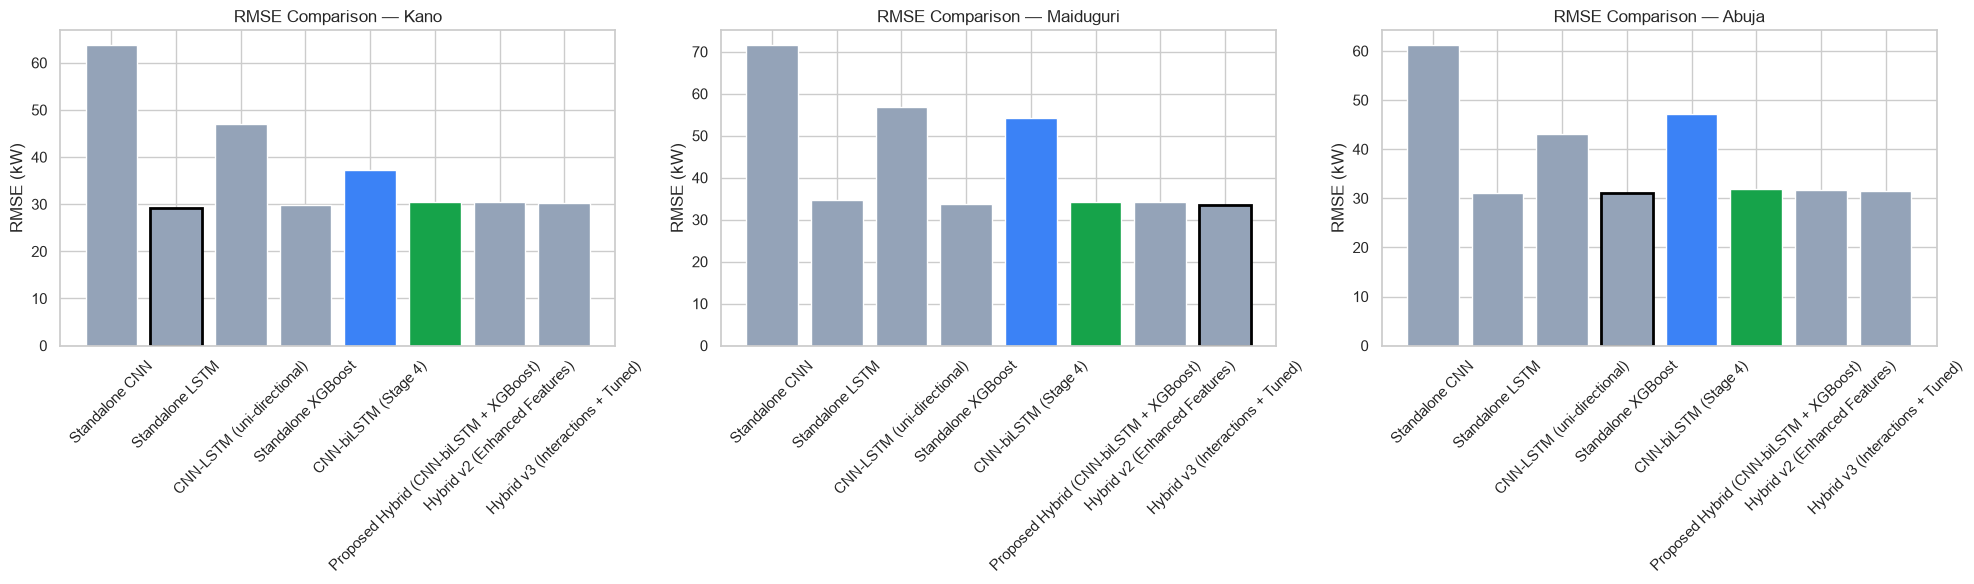

✅ Saved: model_comparison_rmse.png


In [20]:
# ============================================================
# STAGE 7 - CELL 9: Model Comparison Bar Charts
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for idx, city in enumerate(CITIES):
    city_df = comparison_df[comparison_df['City'] == CITY_LABELS[city]]

    ax = axes[idx]
    bars = ax.bar(city_df['Model'], city_df['RMSE (kW)'],
                  color=['#94a3b8']*4 + ['#3b82f6', '#16a34a'])
    ax.set_title(f"RMSE Comparison — {CITY_LABELS[city]}")
    ax.set_ylabel("RMSE (kW)")
    ax.tick_params(axis='x', rotation=45)

    min_idx = city_df['RMSE (kW)'].idxmin()
    for bar, idx2 in zip(bars, city_df.index):
        if idx2 == min_idx:
            bar.set_edgecolor('black')
            bar.set_linewidth(2)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'model_comparison_rmse.png'), dpi=300, bbox_inches="tight")
plt.show()
print("✅ Saved: model_comparison_rmse.png")

In [21]:
# ============================================================
# STAGE 7 - CELL 10: Multi-Metric Composite Ranking
# ============================================================

# For each city, rank every model 1st-6th on EACH metric separately,
# then average the ranks together into one composite score.
# Lower RMSE/MAE/MAPE/nRMSE/nMAE = better (rank 1 = lowest value).
# Higher R² = better, so we rank it in reverse.

RANK_LOWER_IS_BETTER = ['RMSE (kW)', 'MAE (kW)', 'MAPE (%)', 'nRMSE (%)', 'nMAE (%)']
RANK_HIGHER_IS_BETTER = ['R2']

ranked_tables = []

for city in CITIES:
    city_df = comparison_df[comparison_df['City'] == CITY_LABELS[city]].copy()

    rank_cols = []
    for col in RANK_LOWER_IS_BETTER:
        rank_col = f'{col}_rank'
        city_df[rank_col] = city_df[col].rank(ascending=True)
        rank_cols.append(rank_col)

    for col in RANK_HIGHER_IS_BETTER:
        rank_col = f'{col}_rank'
        city_df[rank_col] = city_df[col].rank(ascending=False)
        rank_cols.append(rank_col)

    # Composite score = average rank across all 6 metrics (lower = better overall)
    city_df['Composite_Rank'] = city_df[rank_cols].mean(axis=1)
    city_df = city_df.sort_values('Composite_Rank')

    ranked_tables.append(city_df[['City', 'Model', 'Composite_Rank']])

    print(f"\n{'='*55}")
    print(f"COMPOSITE RANKING — {CITY_LABELS[city]}")
    print(f"{'='*55}")
    print(city_df[['Model', 'Composite_Rank']].to_string(index=False))

final_ranking_df = pd.concat(ranked_tables)
final_ranking_df.to_csv(os.path.join(RESULTS_DIR, 'composite_model_ranking.csv'), index=False)
print(f"\n✅ Saved to: composite_model_ranking.csv")


COMPOSITE RANKING — Kano
                                 Model  Composite_Rank
                       Standalone LSTM        1.000000
                    Standalone XGBoost        2.166667
      Hybrid v3 (Interactions + Tuned)        2.833333
         Hybrid v2 (Enhanced Features)        4.333333
Proposed Hybrid (CNN-biLSTM + XGBoost)        4.666667
                  CNN-biLSTM (Stage 4)        6.000000
            CNN-LSTM (uni-directional)        7.166667
                        Standalone CNN        7.833333

COMPOSITE RANKING — Maiduguri
                                 Model  Composite_Rank
      Hybrid v3 (Interactions + Tuned)        1.333333
                    Standalone XGBoost        2.500000
Proposed Hybrid (CNN-biLSTM + XGBoost)        3.083333
         Hybrid v2 (Enhanced Features)        3.750000
                       Standalone LSTM        4.333333
                  CNN-biLSTM (Stage 4)        6.333333
            CNN-LSTM (uni-directional)        7.000000
        

In [22]:
# ============================================================
# MULTI-RUN VALIDATION - CELL 1: Repeated Training Function
# ============================================================

N_RUNS = 5   # number of independent training repeats per architecture per city

def train_multiple_runs(builder_fn, city, arch_name, n_runs=N_RUNS):
    """
    Trains the given architecture n_runs times, each starting from a
    genuinely different random initialization (different seed per run),
    and returns a list of that run's daytime-only metrics.

    Nothing is saved to disk here — these are one-off diagnostic runs,
    not meant to replace your production saved models.
    """
    run_results = []

    for run_idx in range(n_runs):
        seed = 100 + run_idx   # a distinct, clearly-different seed each run

        np.random.seed(seed)
        tf.random.set_seed(seed)

        model = builder_fn(WINDOW_SIZE, N_FEATURES)

        early_stop = EarlyStopping(
            monitor='val_loss', patience=15,
            restore_best_weights=True, verbose=0
        )
        reduce_lr = ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=7, min_lr=1e-6, verbose=0
        )

        model.fit(
            data[city]['X_train'], data[city]['y_train'],
            validation_data=(data[city]['X_val'], data[city]['y_val']),
            epochs=120, batch_size=64,
            callbacks=[early_stop, reduce_lr],
            verbose=0,
            shuffle=False
        )

        y_pred_norm = model.predict(data[city]['X_test'], verbose=0).flatten()
        metrics = evaluate_model(y_pred_norm, data[city]['y_test'], data[city]['tgt_scaler'])
        run_results.append(metrics)

        print(f"  Run {run_idx+1}/{n_runs} (seed={seed}): "
              f"RMSE={metrics['RMSE']:.2f} | R2={metrics['R2']:.4f}")

    return run_results

In [23]:
# ============================================================
# MULTI-RUN VALIDATION - CELL 2: Execute Multi-Run Training
# ============================================================

builders = {
    'cnn_only':  build_cnn_only,
    'lstm_only': build_lstm_only,
    'cnn_lstm':  build_cnn_lstm,
}

multi_run_results = {}   # multi_run_results[arch_name][city] = list of 5 metric dicts

for arch_name, builder_fn in builders.items():
    multi_run_results[arch_name] = {}
    for city in CITIES:
        print("="*55)
        print(f"MULTI-RUN: {arch_name.upper()} — {CITY_LABELS[city].upper()}")
        print("="*55)
        multi_run_results[arch_name][city] = train_multiple_runs(builder_fn, city, arch_name)
        print()

print("✅ All 45 training runs complete (3 architectures × 3 cities × 5 runs)")

MULTI-RUN: CNN_ONLY — KANO
  Run 1/5 (seed=100): RMSE=45.23 | R2=0.9633
  Run 2/5 (seed=101): RMSE=56.78 | R2=0.9422
  Run 3/5 (seed=102): RMSE=49.25 | R2=0.9565
  Run 4/5 (seed=103): RMSE=46.26 | R2=0.9616
  Run 5/5 (seed=104): RMSE=70.28 | R2=0.9114

MULTI-RUN: CNN_ONLY — MAIDUGURI
  Run 1/5 (seed=100): RMSE=65.59 | R2=0.9218
  Run 2/5 (seed=101): RMSE=80.46 | R2=0.8823
  Run 3/5 (seed=102): RMSE=94.95 | R2=0.8361
  Run 4/5 (seed=103): RMSE=72.25 | R2=0.9051
  Run 5/5 (seed=104): RMSE=80.48 | R2=0.8822

MULTI-RUN: CNN_ONLY — ABUJA
  Run 1/5 (seed=100): RMSE=54.38 | R2=0.9414
  Run 2/5 (seed=101): RMSE=58.12 | R2=0.9331
  Run 3/5 (seed=102): RMSE=54.94 | R2=0.9402
  Run 4/5 (seed=103): RMSE=58.41 | R2=0.9324
  Run 5/5 (seed=104): RMSE=55.45 | R2=0.9391

MULTI-RUN: LSTM_ONLY — KANO
  Run 1/5 (seed=100): RMSE=31.51 | R2=0.9822
  Run 2/5 (seed=101): RMSE=34.80 | R2=0.9783
  Run 3/5 (seed=102): RMSE=32.27 | R2=0.9813
  Run 4/5 (seed=103): RMSE=29.79 | R2=0.9841
  Run 5/5 (seed=104): RMSE=

In [24]:
# ============================================================
# MULTI-RUN VALIDATION - CELL 3: Aggregate Mean ± Std
# ============================================================

aggregated_rows = []

for city in CITIES:
    for arch_name in ['cnn_only', 'lstm_only', 'cnn_lstm']:
        runs = multi_run_results[arch_name][city]

        rmse_vals = [r['RMSE'] for r in runs]
        mae_vals  = [r['MAE']  for r in runs]
        mape_vals = [r['MAPE'] for r in runs]
        r2_vals   = [r['R2']   for r in runs]

        aggregated_rows.append({
            'City': CITY_LABELS[city],
            'Model': MODEL_LABELS[arch_name],
            'RMSE_mean': np.mean(rmse_vals), 'RMSE_std': np.std(rmse_vals),
            'MAE_mean':  np.mean(mae_vals),  'MAE_std':  np.std(mae_vals),
            'MAPE_mean': np.mean(mape_vals), 'MAPE_std': np.std(mape_vals),
            'R2_mean':   np.mean(r2_vals),   'R2_std':   np.std(r2_vals),
        })

    # Add the two deterministic models — Standalone XGBoost and original Hybrid —
    # with std=0 since they're identical every time, no averaging needed
    for model_key in ['xgb_only', 'hybrid']:
        m = results[city][model_key]
        aggregated_rows.append({
            'City': CITY_LABELS[city],
            'Model': MODEL_LABELS[model_key],
            'RMSE_mean': m['RMSE'], 'RMSE_std': 0.0,
            'MAE_mean':  m['MAE'],  'MAE_std':  0.0,
            'MAPE_mean': m['MAPE'], 'MAPE_std': 0.0,
            'R2_mean':   m['R2'],   'R2_std':   0.0,
        })

multi_run_df = pd.DataFrame(aggregated_rows)
multi_run_df.to_csv(os.path.join(RESULTS_DIR, 'multi_run_validated_comparison.csv'), index=False)

for city in CITIES:
    print(f"\n{'='*70}")
    print(f"MULTI-RUN VALIDATED COMPARISON — {CITY_LABELS[city]}")
    print(f"{'='*70}")
    city_df = multi_run_df[multi_run_df['City'] == CITY_LABELS[city]].copy()
    city_df['RMSE'] = city_df.apply(lambda r: f"{r['RMSE_mean']:.2f} ± {r['RMSE_std']:.2f}", axis=1)
    city_df['R2']   = city_df.apply(lambda r: f"{r['R2_mean']:.4f} ± {r['R2_std']:.4f}", axis=1)
    print(city_df[['Model', 'RMSE', 'R2']].sort_values('RMSE_mean' if False else 'Model').to_string(index=False))

print(f"\n✅ Saved to: multi_run_validated_comparison.csv")


MULTI-RUN VALIDATED COMPARISON — Kano
                                 Model         RMSE              R2
            CNN-LSTM (uni-directional) 44.01 ± 4.69 0.9649 ± 0.0075
Proposed Hybrid (CNN-biLSTM + XGBoost) 30.55 ± 0.00 0.9833 ± 0.0000
                        Standalone CNN 53.56 ± 9.29 0.9470 ± 0.0193
                       Standalone LSTM 32.75 ± 2.08 0.9807 ± 0.0024
                    Standalone XGBoost 29.81 ± 0.00 0.9841 ± 0.0000

MULTI-RUN VALIDATED COMPARISON — Maiduguri
                                 Model         RMSE              R2
            CNN-LSTM (uni-directional) 55.86 ± 3.27 0.9431 ± 0.0066
Proposed Hybrid (CNN-biLSTM + XGBoost) 34.11 ± 0.00 0.9788 ± 0.0000
                        Standalone CNN 78.75 ± 9.84 0.8855 ± 0.0289
                       Standalone LSTM 40.34 ± 5.23 0.9699 ± 0.0079
                    Standalone XGBoost 33.72 ± 0.00 0.9793 ± 0.0000

MULTI-RUN VALIDATED COMPARISON — Abuja
                                 Model         RMSE          